In [1]:
import json, math, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


SUPERFICIE, TINTA = "#fcfcfb", "#0b0b0b"
TINTA_2, MUDO     = "#52514e", "#898781"
GRADE, EIXO       = "#e1e0d9", "#c3c2b7"
REAL, PREDITO     = "#2a78d6", "#eb6834"   # slots categoricos 1 e 2
ERRO_CLARO, MAE_ESC = "#86b6ef", "#184f95" # rampa azul: degraus 250 e 600

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "system-ui", "DejaVu Sans"],
    "figure.facecolor": SUPERFICIE,
    "axes.facecolor": SUPERFICIE,
})



SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
NL = chr(10)   # evita barra invertida no fonte; usado nos relatorios


DATA_DIR = Path.cwd().parent / "data" / "raw"

print(f"dados em {DATA_DIR}")
print(f"semente: {SEED}")

dados em c:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\data\raw
semente: 42


In [ ]:
ARQUIVOS = (
    sorted(DATA_DIR.rglob("ifpe*.csv"))
)
CAMINHOS = {p.stem: p for p in ARQUIVOS}   # para reconferir contra o CSV bruto no fim
print(f"{len(ARQUIVOS)} arquivos" + NL)

def enfeitar(ax, titulo, xlabel, ylabel):
        ax.set_title(titulo, color=TINTA, fontsize=12, loc="left", pad=10)
        ax.set_xlabel(xlabel, color=TINTA_2, fontsize=10)
        ax.set_ylabel(ylabel, color=TINTA_2, fontsize=10)
        ax.grid(True, color=GRADE, linewidth=0.6, linestyle="-")
        ax.set_axisbelow(True)
        for lado in ("top", "right"):
            ax.spines[lado].set_visible(False)
        for lado in ("left", "bottom"):
            ax.spines[lado].set_color(EIXO)
        ax.tick_params(colors=MUDO, labelsize=9)

def load_file(p: Path):
    df = pd.read_csv(p, encoding="utf-8-sig")
    df.columns = [c.strip() for c in df.columns]
    df["datetime"] = pd.to_datetime(df["datetime"])
    return df

partes = []
for p in ARQUIVOS:
    df = load_file(p)
    df['station'] = p.stem.split('_')[0]
    partes.append(df)
    print(f"  {p.parent.name:10} {p.stem:16} {len(df):7} linhas  {len(df.columns):2} colunas")

def show_dataset(dataset: pd.DataFrame):
    # A ordem das colunas difere entre os schemas; a uniao e por nome.
    print(NL + f"pool: {len(dataset)} linhas, {dataset.shape[1]} colunas")
    print(NL + "nulos por coluna (so as que tem):")
    nulos = dataset.isna().sum()
    print(nulos[nulos > 0].to_string() if (nulos > 0).any() else "  (nenhum)")
    print(NL + "colunas com zero:")
    zeros = dataset.isin([0]).sum()
    print(zeros[zeros > 0].to_string() if (zeros > 0).any() else "  (nenhum)")
    return dataset
    


raw: pd.DataFrame = pd.concat(partes, ignore_index=True)

9 arquivos

  raw        ifpee1_2021        45872 linhas  18 colunas
  raw        ifpee1_2022        43750 linhas  18 colunas
  raw        ifpee1_2023        46380 linhas  18 colunas
  raw        ifpee1_2024        46514 linhas  19 colunas
  raw        ifpee1_2025        44969 linhas  19 colunas
  raw        ifpee2_2024        46514 linhas  19 colunas
  raw        ifpee2_2025        44969 linhas  19 colunas
  raw        ifpee3_2024        46514 linhas  19 colunas
  raw        ifpee3_2025        44969 linhas  19 colunas


In [ ]:

# remover colunas "mortas"
REMOVE_COLS = {"ano", 'velocidade_vento', 'condicao' }
raw = raw.drop(columns=[c for c in REMOVE_COLS if c in raw.columns])

df = raw[raw.station ].copy()

df.PCA = df.PCA.fillna(0)

show_dataset(df).head()


pool: 410451 linhas, 17 colunas

nulos por coluna (so as que tem):
  (nenhum)

colunas com zero:
PCA    9683


,temperatura_ambiente,timestamp,doy,ghi_cs,hora_dec,kc,angzen,ghit,PCA,jacques,sandia,sandia_cell,pvsyst_cell,datetime,ioeff,kt,station
0,29.740,2021-01-04 10:09:00,4,971.194471,10.150000,1.058490,25.263877,924.576334,1.28,53.714096,53.072812,60.619963,55.564373,2021-01-04 10:05:00,1411.074617,0.805575,ifpee1
1,30.222,2021-01-04 10:12:00,4,976.384198,10.200000,1.059624,24.284699,935.169209,1.70,55.256880,54.528103,62.127197,56.342243,2021-01-04 10:10:00,1411.074617,0.804377,ifpee1
2,30.548,2021-01-04 10:17:00,4,984.658595,10.283333,1.080374,23.325885,966.293219,1.72,56.416083,55.663052,63.515055,57.537569,2021-01-04 10:15:00,1411.074617,0.820995,ifpee1
3,30.900,2021-01-04 10:22:00,4,992.418037,10.366667,0.846297,22.390090,786.259644,1.70,51.416415,50.859537,57.272172,52.861045,2021-01-04 10:20:00,1411.074617,0.643736,ifpee1
4,29.426,2021-01-04 10:27:00,4,999.658520,10.450000,0.742374,21.480359,710.256671,1.00,48.439875,47.886373,53.657849,49.264204,2021-01-04 10:25:00,1411.074617,0.565181,ifpee1


In [4]:
d2 = df.copy()
d2["hora"] = d2.datetime.dt.hour
d2["mes"] = d2.datetime.dt.month

ESTACOES = sorted(d2["station"].unique())
print(f"{len(d2)} linhas, {len(ESTACOES)} estacoes: {', '.join(ESTACOES)}")

410451 linhas, 3 estacoes: ifpee1, ifpee2, ifpee3


In [5]:
df = show_dataset(df[df.PCA != 0].reset_index())


pool: 400768 linhas, 18 colunas

nulos por coluna (so as que tem):
  (nenhum)

colunas com zero:
index    1


Text(0.5, 0.98, 'PCA por hora do dia')

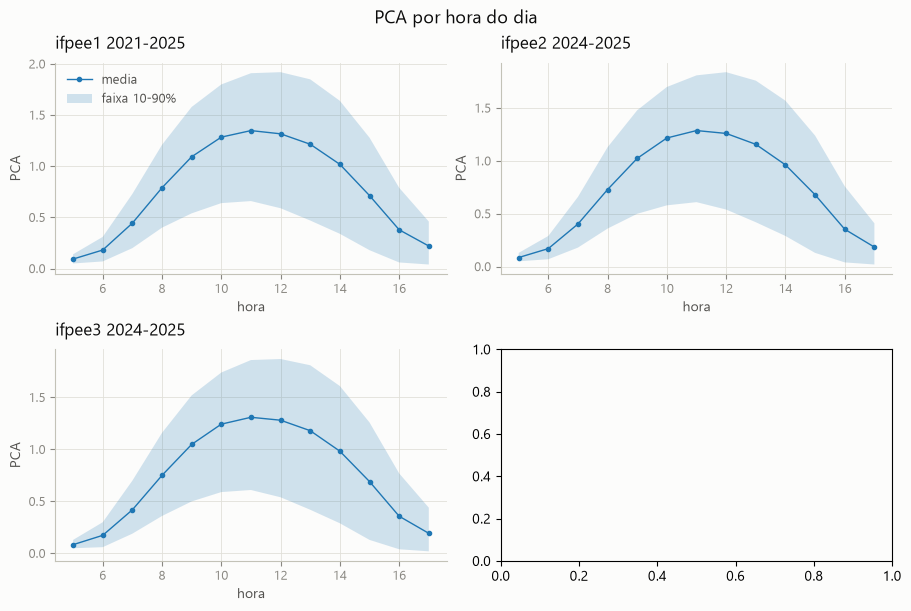

In [6]:
# 1) PCA por hora do dia, uma estacao por painel (media + faixa 10-90%)
lines = (len(d2.station.unique()) / 2).__round__()
fig, axs = plt.subplots(lines, 2, figsize=(9, 3 * lines), constrained_layout=True)
for ax, (nome, d) in zip(axs.flat, d2.groupby("station")):
    g = d.groupby("hora")["PCA"]
    ax.plot(g.mean().index, g.mean().values, marker=".", lw=1, label="media")
    ax.fill_between(g.mean().index, g.quantile(0.1).values, g.quantile(0.9).values,
                    alpha=0.2, label="faixa 10-90%")
    enfeitar(ax, f"{nome} {d.datetime.dt.year.min()}-{d.datetime.dt.year.max()}", "hora", "PCA")
axs.flat[0].legend(frameon=False, fontsize=9, labelcolor=TINTA_2)
fig.suptitle("PCA por hora do dia", color=TINTA, fontsize=13)

Text(0.5, 0.98, 'PCA por mes')

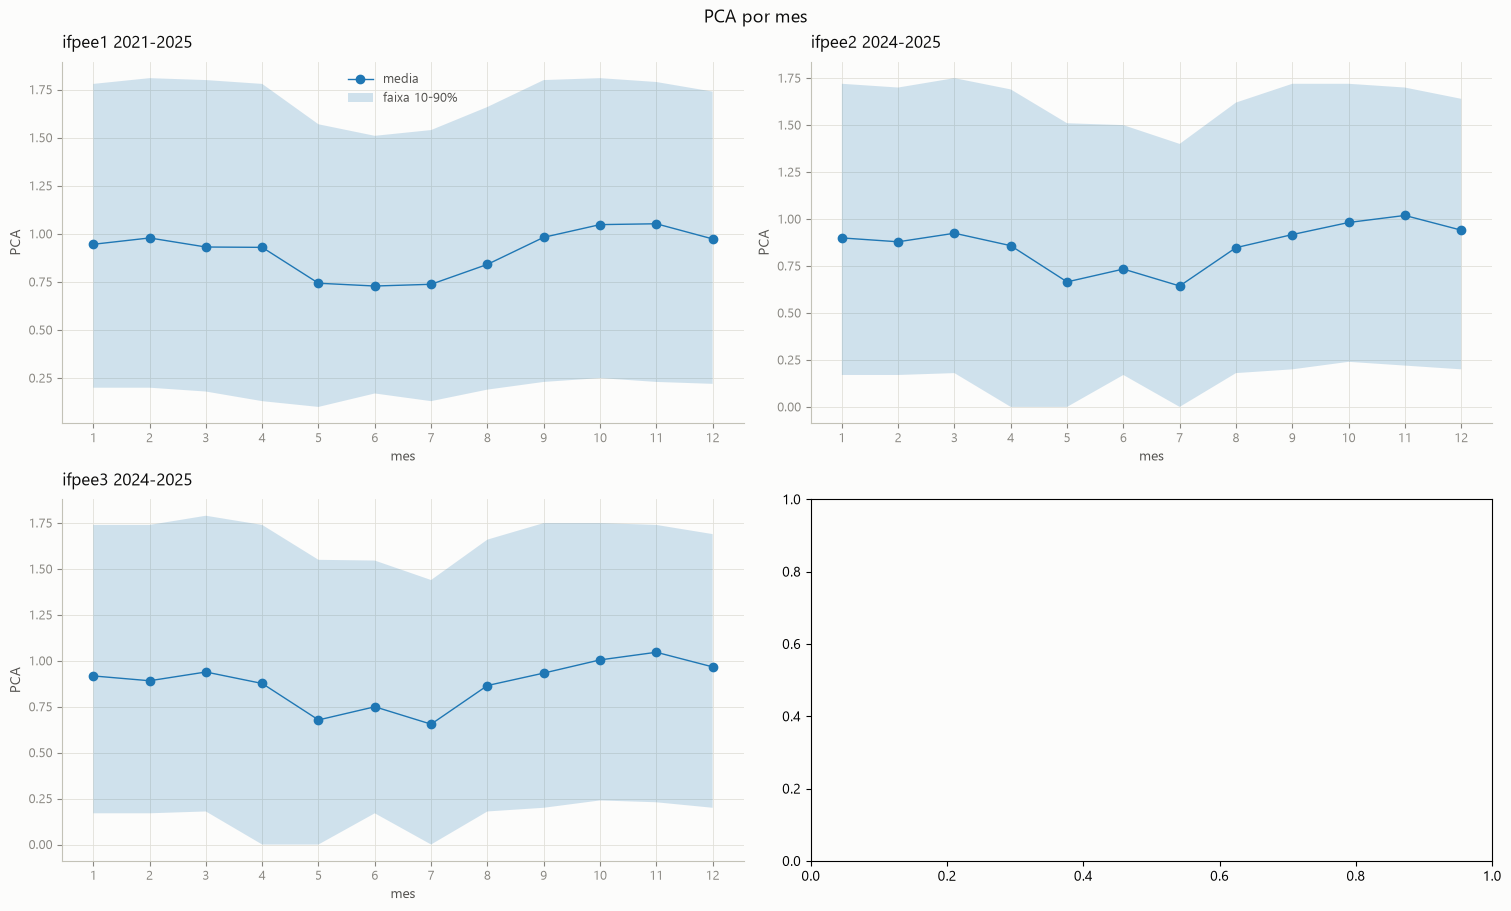

In [7]:
# 2) PCA por mes, uma estacao por painel (media + faixa 10-90%)
fig, axs = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)
for ax, (nome, d) in zip(axs.flat, d2.groupby("station")):
    gm = d.groupby("mes")["PCA"]
    ax.plot(gm.mean().index, gm.mean().values, marker="o", lw=1, label="media")
    ax.fill_between(gm.mean().index, gm.quantile(0.1).values, gm.quantile(0.9).values,
                    alpha=0.2, label="faixa 10-90%")
    ax.set_xticks(range(1, 13))
    enfeitar(ax, f"{nome} {d.datetime.dt.year.min()}-{d.datetime.dt.year.max()}", "mes", "PCA")
axs.flat[0].legend(frameon=False, fontsize=9, labelcolor=TINTA_2)
fig.suptitle("PCA por mes", color=TINTA, fontsize=13)

Text(0.5, 0.98, 'PCA: hora x mes (media)')

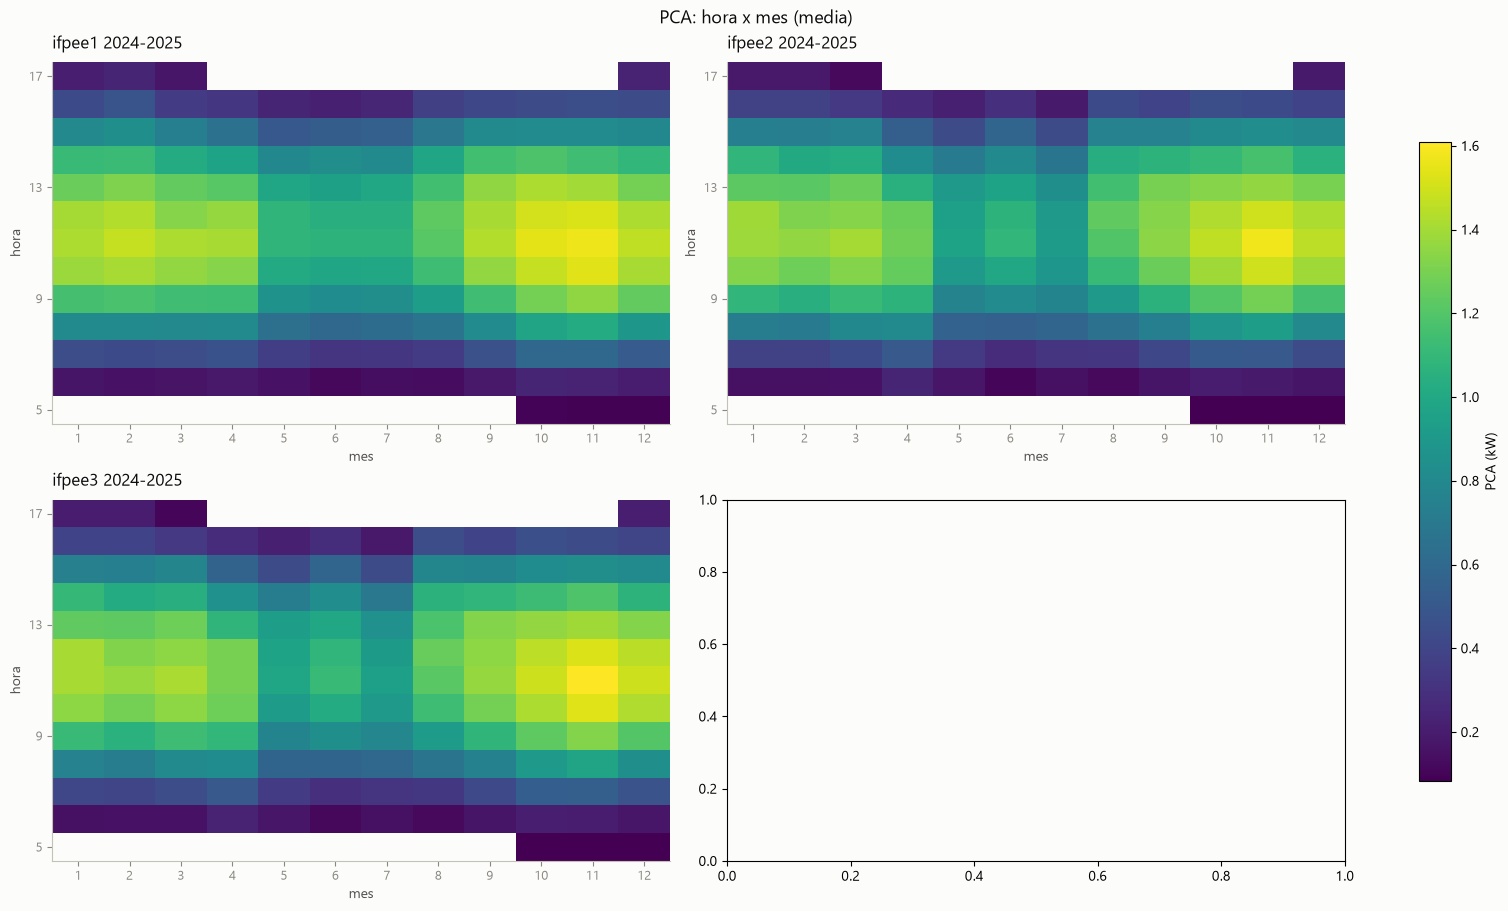

In [8]:
# 3) Heatmap hora x mes, uma estacao por painel (mesma escala de cor)
tabs = {nome: d.pivot_table(index="hora", columns="mes", values="PCA", aggfunc="mean")
        for nome, d in d2.groupby("station")}
vmin = min(np.nanmin(t.to_numpy()) for t in tabs.values())
vmax = max(np.nanmax(t.to_numpy()) for t in tabs.values())

fig, axs = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)
for ax, (nome, tab) in zip(axs.flat, tabs.items()):
    im = ax.imshow(tab.to_numpy(), aspect="auto", origin="lower", cmap="viridis",
                   vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(tab.columns)), tab.columns)
    ax.set_yticks(range(0, len(tab.index), 4), tab.index[::4])
    enfeitar(ax, f"{nome} {d.datetime.dt.year.min()}-{d.datetime.dt.year.max()}", "mes", "hora")
    ax.grid(False)
fig.colorbar(im, ax=axs, label="PCA (kW)", shrink=0.8)
fig.suptitle("PCA: hora x mes (media)", color=TINTA, fontsize=13)

Text(0.5, 0.98, 'Produtividade do sistema: PCA / ghit')

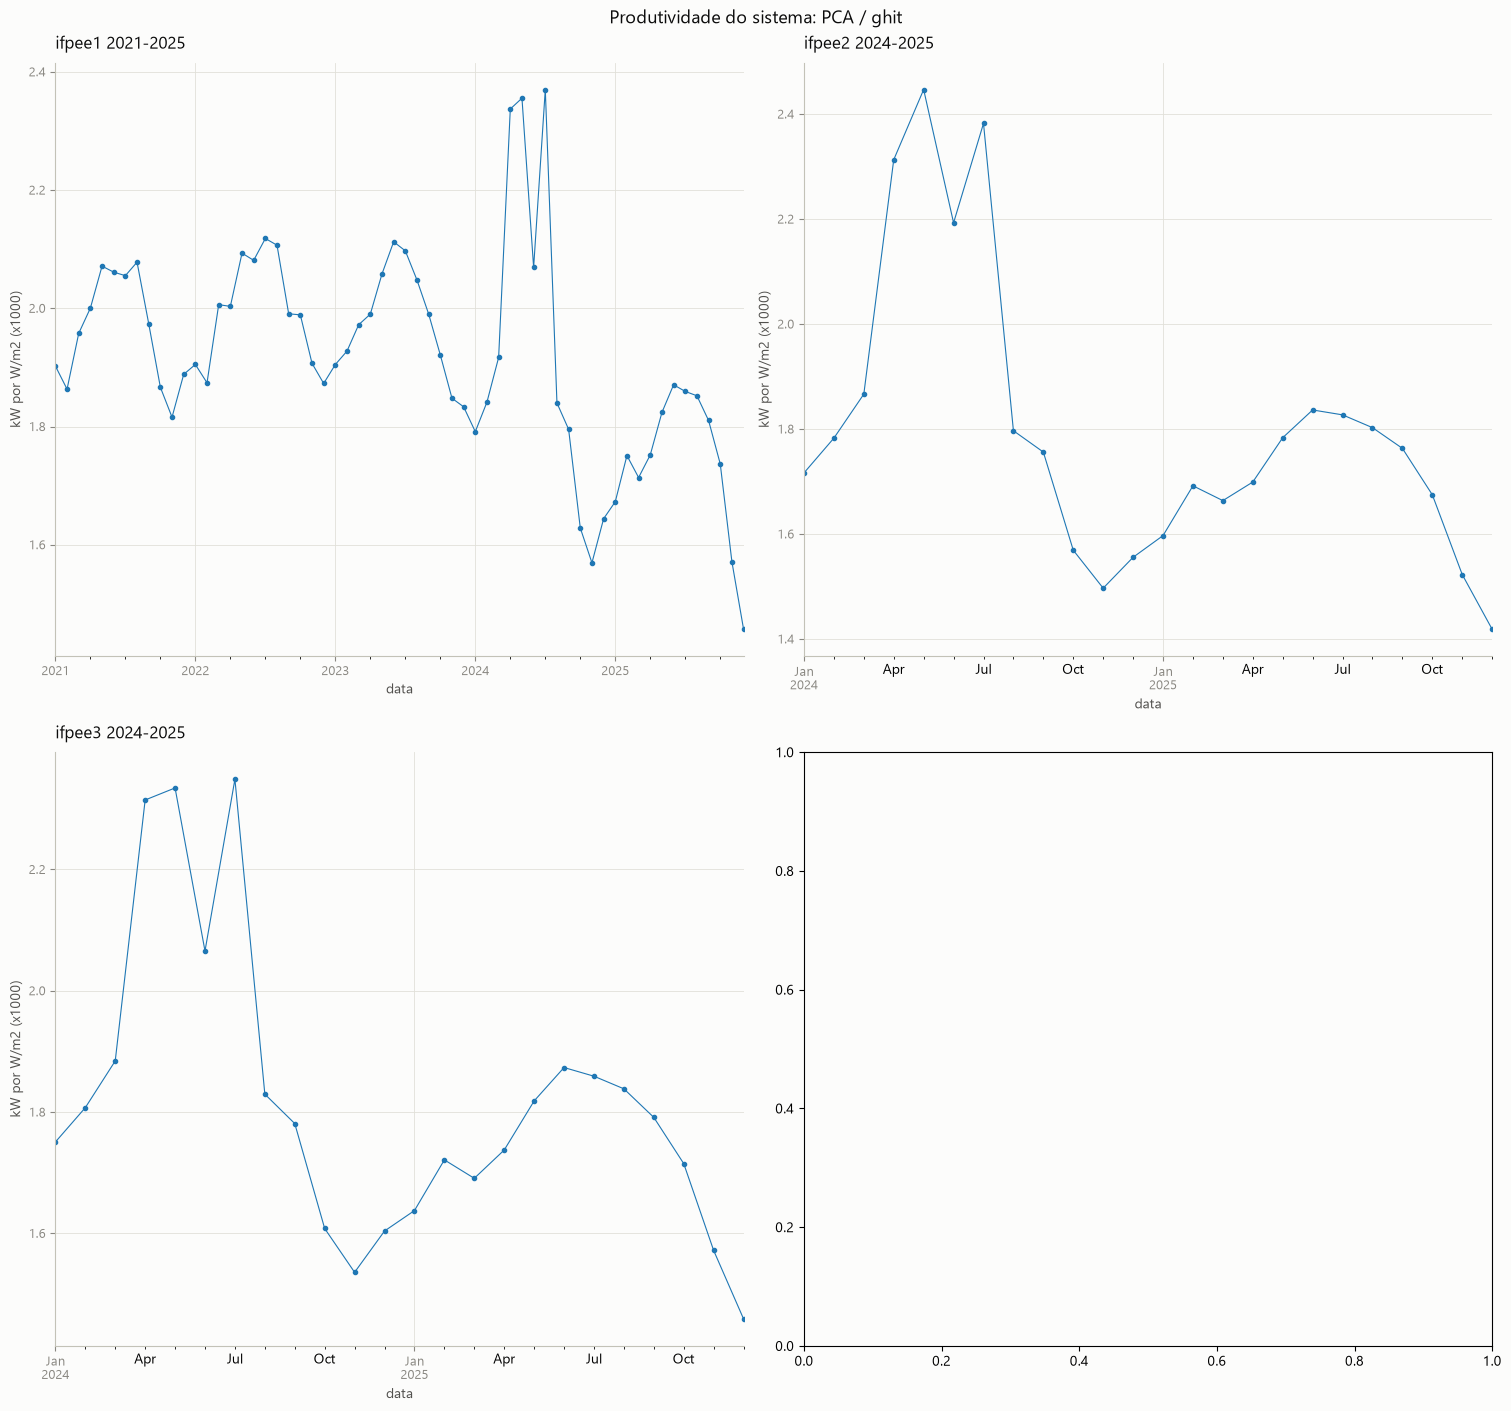

In [10]:
# 4) Eficiencia do sistema PCA / ghit (media diaria, x1000), uma estacao por painel.
# A razao cancela a sazonalidade de sol; o que sobra e' o estado do sistema.
fig, axs = plt.subplots(2, 2, figsize=(15, 14), constrained_layout=True)
for ax, (nome, d) in zip(axs.flat, d2.groupby("station")):
    dd = d[(d.PCA != 0) & (d.ghit > 0)]
    dd['ef'] = dd.PCA / dd.ghit
    dd = dd.groupby(dd["datetime"].dt.to_period("2M")).agg({
        'ef': 'mean',
        'datetime': 'first'
    })
    ef = dd.ef
    (ef * 1000).plot(ax=ax, marker=".", lw=0.8)
    enfeitar(ax, f"{nome} {dd.datetime.dt.year.min()}-{dd.datetime.dt.year.max()}", "data", "kW por W/m2 (x1000)")
fig.suptitle("Produtividade do sistema: PCA / ghit", color=TINTA, fontsize=13)

In [ ]:
key = ["station", pd.Grouper(key="datetime", freq="1h")]

zeros = (
    df.assign(_zero=(df['PCA'] == 0).astype(int))
      .groupby(key)['_zero']
      .sum()
)
media = df.loc[df['PCA'] != 0].groupby(key)['PCA'].sum()

agg = df.groupby(key).agg({
    'PCA': 'sum',
    'temperatura_ambiente': 'mean',
    'ghit': 'first',
    'doy': 'first',
    'ghi_cs': 'mean',
    'kc': 'mean',
    'angzen': 'mean',
    'jacques': 'mean',
    'sandia': 'mean',
    'sandia_cell': 'mean',
    'pvsyst_cell': 'mean',
    'ioeff': 'mean',
    'kt': 'mean',
    # 'station' e 'datetime' REMOVIDOS — virão do índice
})

zeros_full = zeros.reindex(agg.index, fill_value=0)
media_full = media.reindex(agg.index)
agg['PCA'] = media_full.where(zeros_full <= 1)

df = show_dataset(agg.reset_index())   # gera as colunas 'station' e 'datetime'


pool: 36061 linhas, 15 colunas

nulos por coluna (so as que tem):
  (nenhum)

colunas com zero:
  (nenhum)


ifpee1: 20152 horas na serie |  2129 faltando ( 9.7%) |    0 com PCA nulo ( 0.0%) | 2021-01-04 10:00:00 .. 2025-12-31 17:00:00
ifpee2:  7954 horas na serie |   983 faltando (11.2%) |    0 com PCA nulo ( 0.0%) | 2024-01-01 06:00:00 .. 2025-12-31 17:00:00
ifpee3:  7955 horas na serie |   982 faltando (11.2%) |    0 com PCA nulo ( 0.0%) | 2024-01-01 06:00:00 .. 2025-12-31 17:00:00


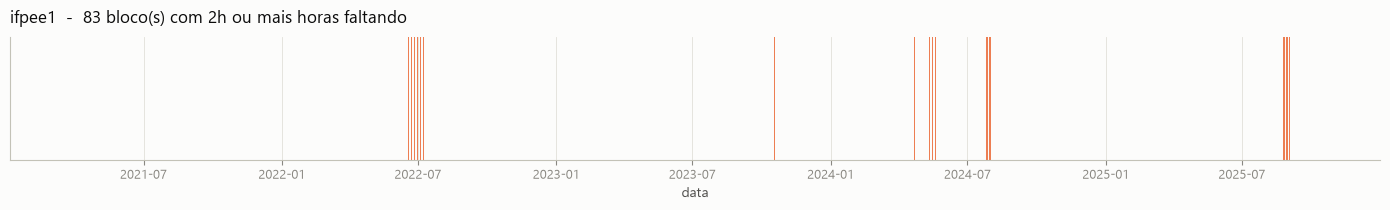

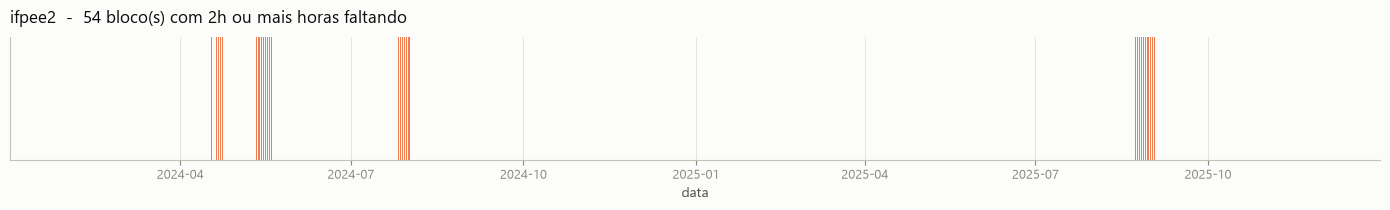

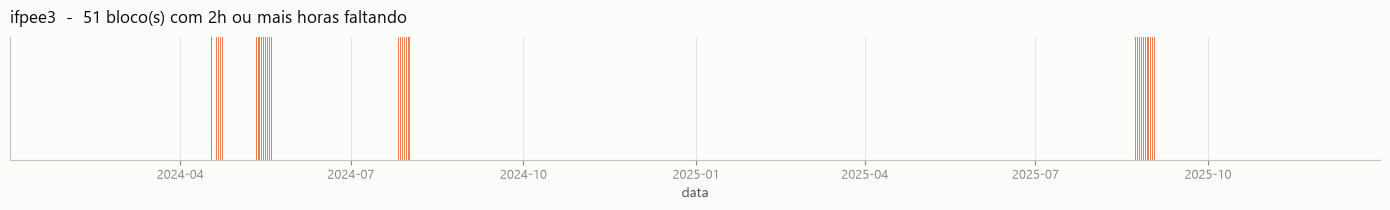

In [ ]:
# Horas faltando em relacao a um eixo de 1h, por estacao (janela propria).
def blocos(idx):
  """Agrupa um DatetimeIndex em blocos de horas consecutivas."""
  if len(idx) == 0:
    return []
  s = pd.Series(idx)
  g = (s.diff() != pd.Timedelta(hours=1)).cumsum()
  return [(b.iloc[0], b.iloc[-1], len(b)) for _, b in s.groupby(g)]

faltando = {}
for est, d_est in df.groupby("station"):
  esperado = pd.date_range(d_est.datetime.min(), d_est.datetime.max(), freq="1h")
  esperado = esperado[esperado.hour > 5]
  esperado = esperado[esperado.hour < 18]
  ausentes = esperado.difference(d_est.datetime)
  nulos    = d_est.PCA.isna().sum()          # linha existe, PCA mascarado (2+ zeros)
  faltando[est] = ausentes
  pct_ausentes = 100 * len(ausentes) / len(esperado)
  pct_nulos    = 100 * nulos / len(esperado)
  print(f"{est}: {len(d_est):5} horas na serie | {len(ausentes):5} faltando "
        f"({pct_ausentes:4.1f}%) | {nulos:4} com PCA nulo ({pct_nulos:4.1f}%) | "
        f"{esperado[0]} .. {esperado[-1]}")

for est, ausentes in faltando.items():
  bs = [(ini, fim, n) for ini, fim, n in blocos(ausentes) if n >= 2]
  if bs:
    d_est = df[df.station == est]
    fig, ax = plt.subplots(figsize=(14, 2.2))
    # uma barra por bloco, do início ao fim (inclusive)
    faixas = [(ini, (fim - ini) + pd.Timedelta(hours=1)) for ini, fim, _ in bs]
    ax.broken_barh(faixas, (0, 1), facecolors=PREDITO, edgecolors="none", alpha=0.85)
    ax.set_xlim(d_est.datetime.min(), d_est.datetime.max())
    ax.set_ylim(0, 1)
    ax.set_yticks([])
    enfeitar(ax, f"{est}  -  {len(bs)} bloco(s) com 2h ou mais horas faltando", "data", "")
    plt.tight_layout()
    plt.show()
  bs = []  # já mostrado no gráfico; evita a listagem textual
  for ini, fim, n in bs[:20]:
    print(f"  {ini} .. {fim}  ({n} h)")
  if len(bs) > 20:
    print(f"  ... mais {len(bs) - 20} bloco(s)")




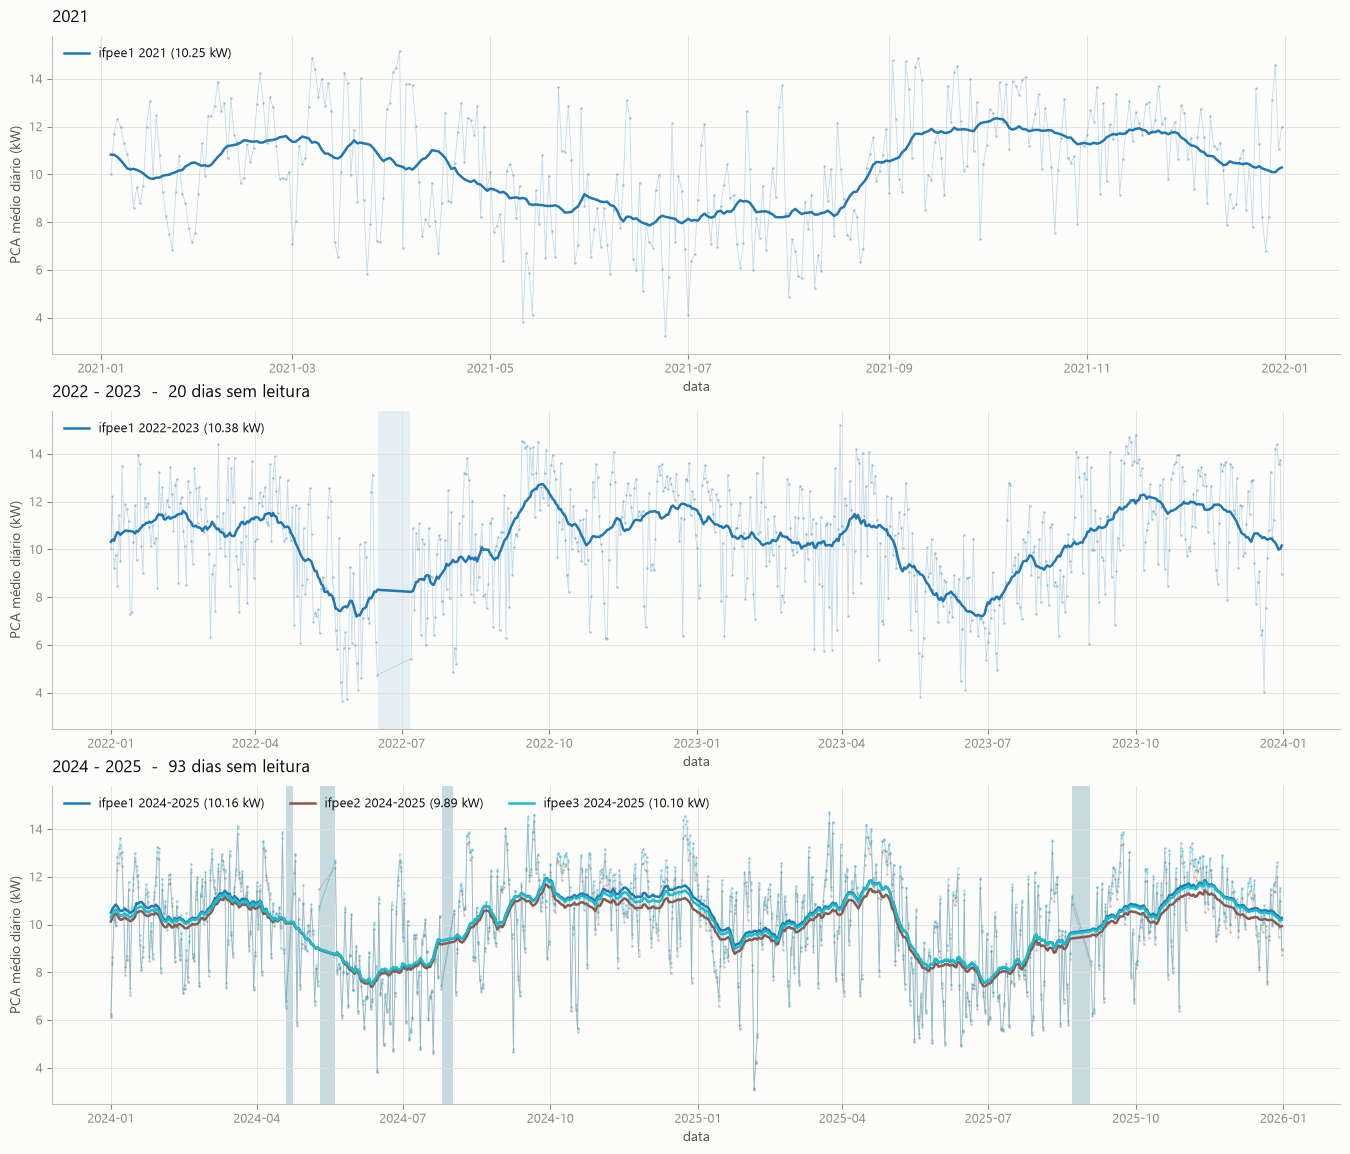

In [ ]:
def plot_time_series(dataset, janela=7):
        d = dataset[dataset.PCA != 0].copy()
        d["ano"] = d["datetime"].dt.year
        d["dia"] = d["datetime"].dt.normalize()
        anos, estacoes = sorted(d["ano"].unique()), sorted(d["station"].unique())
        cores = dict(zip(estacoes, plt.cm.tab10(np.linspace(0, 1, len(estacoes)))))

        # pares montados DE TRAS PARA FRENTE: com contagem impar, o ano mais antigo
        # fica sozinho e o ULTIMO ano sempre tem um par.
        pares, i = [], len(anos)
        while i > 0:
                pares.append(anos[max(i - 2, 0):i])
                i -= 2
        pares.reverse()

        # sharey alinha a escala dos paineis -> leitura continua ao rolar.
        fig, axs = plt.subplots(len(pares), 1, figsize=(14, 4 * len(pares)),
                                                        squeeze=False, sharey=True)

        for ax, par in zip(axs.ravel(), pares):
                falhas = 0
                for est in estacoes:
                        d_est = d[(d["station"] == est) &
                                          (d["ano"] >= par[0]) & (d["ano"] <= par[-1])]
                        if d_est.empty:
                                continue

                        # UMA serie por par: ao agrupar pelo dia real, os dois anos
                        # ficam encadeados no eixo do tempo (jan/ano1 ... dez/ano2),
                        # sem quebra na virada do ano.
                        serie = d_est.groupby("dia")["PCA"].mean().sort_index()
                        cor = cores[est]

                        # linha unica (sem alternar '-'/'- -' entre anos: isso partia a
                        # serie em dois trechos visuais e quebrava a continuidade).
                        ax.plot(serie.index, serie.values, color=cor, lw=0.6, alpha=0.25,
                                        marker=".", ms=2)
                        rotulo = f"{est} {par[0]}" if len(par) == 1 else f"{est} {par[0]}-{par[-1]}"
                        ax.plot(serie.rolling(janela, center=True, min_periods=1).mean(),
                                        color=cor, lw=1.8,
                                        label=f"{rotulo} ({serie.mean():.2f} kW)")

                        # gaps: dias sem leitura dentro do intervalo observado
                        esperado = pd.date_range(serie.index.min(), serie.index.max(), freq="D")
                        faltando = esperado.difference(serie.index)
                        if len(faltando):
                                blocos = faltando.to_series().diff().ne(pd.Timedelta(days=1)).cumsum()
                                for _, bloco in faltando.to_series().groupby(blocos):
                                        ax.axvspan(bloco.iloc[0] - pd.Timedelta(hours=12),
                                                           bloco.iloc[-1] + pd.Timedelta(hours=12),
                                                           facecolor=cor, alpha=0.10, zorder=0)
                                falhas += len(faltando)

                titulo = str(par[0]) if len(par) == 1 else f"{par[0]} - {par[-1]}"
                if falhas:
                        titulo += f"  -  {falhas} dias sem leitura"
                enfeitar(ax, titulo, "data", "PCA médio diário (kW)")
                ax.legend(frameon=False, loc="upper left", fontsize=9,
                                  labelcolor=TINTA, ncol=3)

        fig.subplots_adjust(top=0.94, bottom=0.05, left=0.06, right=0.98, hspace=0.18)
        plt.show()

plot_time_series(df.reset_index(), janela=30)


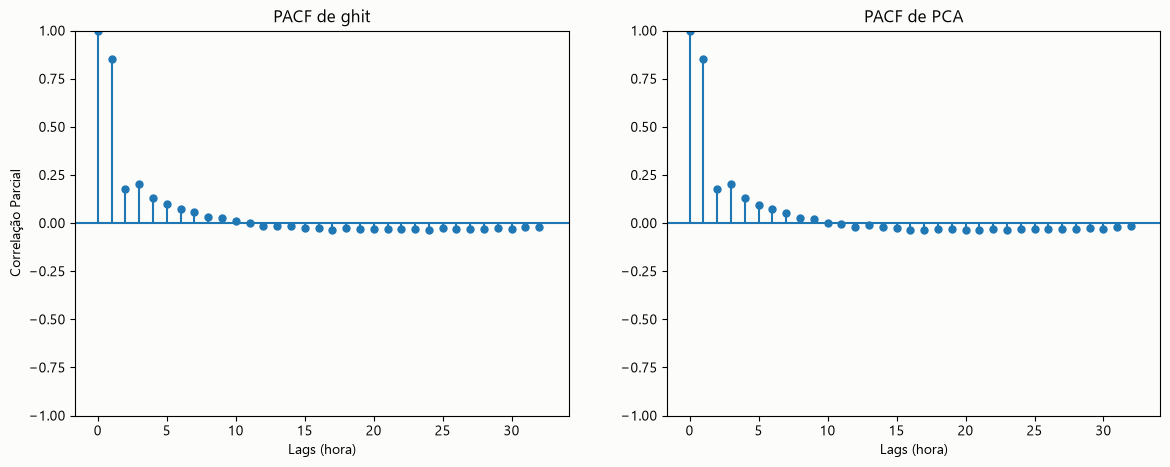

In [11]:
from statsmodels.graphics.tsaplots import plot_pacf

df_a = df.copy()  # remove 2024, que tem perda de dados


fig, ax =plt.subplots(ncols=2, figsize=(14, 5))
plot_pacf(df_a.ghit, ax=ax[0], lags=32, method="ywm", title="PACF de ghit")
plot_pacf(df_a.PCA, ax=ax[1], lags=32, method="ywm", title="PACF de PCA")


# 3. Exibindo o gráfico
ax[0].set_xlabel("Lags (hora)")
ax[0].set_ylabel("Correlação Parcial")
ax[1].set_xlabel("Lags (hora)")

plt.show()

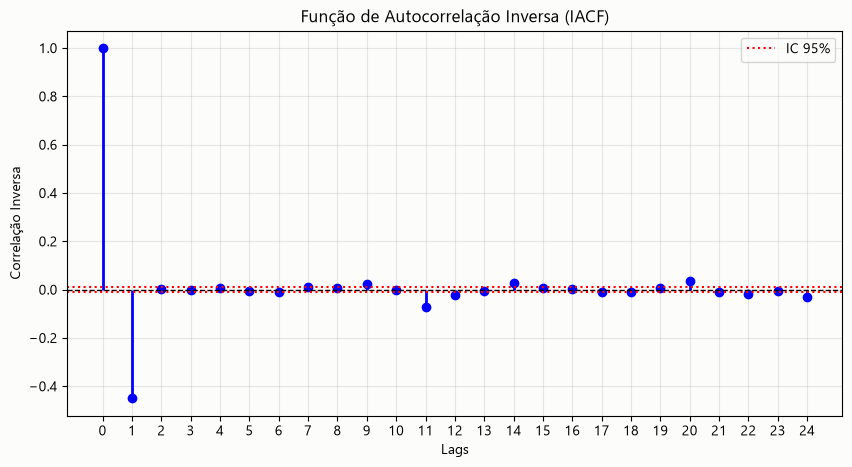

In [ ]:
from statsmodels.regression.linear_model import yule_walker

def plot_iacf(series, lags=20):
    """
    Calcula e plota a Função de Autocorrelação Inversa (IACF)
    baseada na aproximação por um modelo autorregressivo de alta ordem.
    """
    # Remove valores nulos caso existam na série do Pandas
    series = series.dropna()
    n = len(series)
    
    # 1. Ajusta um modelo AR de alta ordem (Yule-Walker)
    # Geralmente usa-se a ordem sugerida pela metade das observações ou um limite prático
    ar_order = min(lags * 2, n // 3)
    ar_coefs, _ = yule_walker(series, order=ar_order, demean=True)
    
    # 2. Convoluciona os coeficientes AR com eles mesmos para obter a IACF aproximada
    # Adiciona 1 no início para representar o lag 0
    ar_operator = np.r_[1, -ar_coefs]
    iacf_raw = np.correlate(ar_operator, ar_operator, mode='full')
    
    # Pega apenas a metade positiva (lags de 0 em diante)
    iacf = iacf_raw[len(iacf_raw)//2 : len(iacf_raw)//2 + lags + 1]
    
    # Normaliza para que o lag 0 seja igual a 1
    iacf = iacf / iacf[0]

    # Remove lags muito baixos para evitar ruído visual (opcional)
    # iacf = np.where(np.abs(iacf) < 0.1, 0, iacf)
    
    # 3. Monta o gráfico no estilo clássico do statsmodels
    fig, ax = plt.subplots(figsize=(10, 5))
    
    # Plota as barras verticais para os lags de 1 até o limite definido
    x_lags = np.arange(len(iacf))
    ax.vlines(x_lags, 0, iacf, colors='b', lw=2)
    ax.plot(x_lags, iacf, 'bo')
    ax.axhline(0, color='black', linestyle='--', linewidth=1)
    
    # Limites de significância estatística aproximados (IC de 95%)
    conf_level = 1.96 / np.sqrt(n)
    ax.axhline(conf_level, color='red', linestyle=':', label='IC 95%')
    ax.axhline(-conf_level, color='red', linestyle=':')
    
    ax.set_title("Função de Autocorrelação Inversa (IACF)")
    ax.set_xlabel("Lags")
    ax.set_ylabel("Correlação Inversa")
    ax.set_xticks(x_lags)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

plot_iacf(df.PCA, lags=24)


O valor ideal de Lambda (λ) encontrado foi: 0.6650


C:\Users\gusta\AppData\Local\Temp\ipykernel_28040\3286598770.py:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


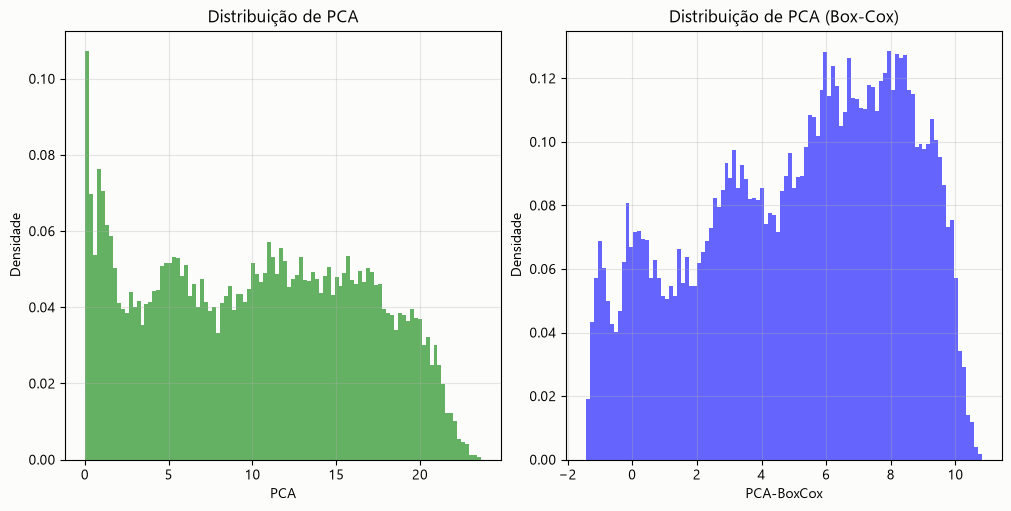

In [ ]:
from scipy import stats

d = df[df.PCA != 0].copy().reset_index(drop=True)
d['PCA-BoxCox'], lmbda = stats.boxcox(d['PCA'])  # Adiciona um pequeno valor para evitar log(0)

print(f"\nO valor ideal de Lambda (λ) encontrado foi: {lmbda:.4f}")

fig, ax = plt.subplots(figsize=(10, 5), ncols=2, constrained_layout=True)
ax[0].hist(d['PCA'], bins=100, density=True, alpha=0.6, color='g')
ax[0].set_title("Distribuição de PCA")
ax[0].set_xlabel("PCA")
ax[0].set_ylabel("Densidade")
ax[0].grid(alpha=0.3)

# Plot the Box-Cox transformed data
ax[1].hist(d['PCA-BoxCox'], bins=100, density=True, alpha=0.6, color='b')
ax[1].set_title("Distribuição de PCA (Box-Cox)")
ax[1].set_xlabel("PCA-BoxCox")
ax[1].set_ylabel("Densidade")
ax[1].grid(alpha=0.3)

fig.show()

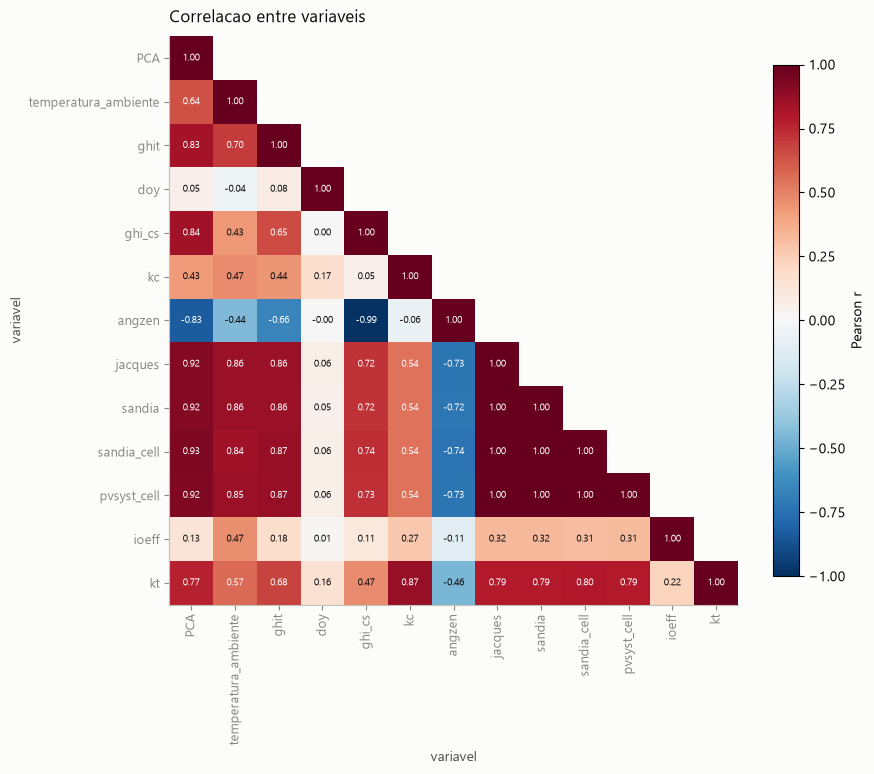

In [ ]:
# Correlation matrix
corr_matrix = df.select_dtypes(include=[np.number]).corr()
# heatmap da matriz de correlacao (so o triangulo inferior; a matriz e' simetrica)
n = len(corr_matrix)
mask = np.triu(np.ones((n, n), dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr_matrix.mask(mask).to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(n), corr_matrix.columns, rotation=90)
ax.set_yticks(range(n), corr_matrix.index)
ax.set_aspect("equal")
enfeitar(ax, "Correlacao entre variaveis", "variavel", "variavel")
ax.grid(False)

# anota o valor de Pearson dentro de cada celula
for r in range(n):
  for c in range(n):
    if c <= r:
      v = corr_matrix.iloc[r, c]
      ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=7,
          color=SUPERFICIE if abs(v) > 0.5 else TINTA)

plt.colorbar(im, ax=ax, label="Pearson r", shrink=0.8)
plt.tight_layout()
plt.show()